In [1]:
# ==================== 각자 수정 ====================
from pathlib import Path

VMMR_ROOT  = Path(r"/Users/yuhuiseon/Downloads/dataset/VMMRdb")   # 내 컴퓨터의 VMMRdb 폴더
CACHE_ROOT = Path("cache")       # 리사이즈 캐시를 저장할 폴더 (git에 올리지 않음)
BUILD_CACHE = False              # True: 짧은 변 256px 캐시를 만든다 (처음 1회, 약 2GB) → 03 학습이 훨씬 빨라짐
# ==================================================

# 02. 데이터 파이프라인 — 학습용 이미지 목록과 분할 만들기

01 노트북에서 정한 **50개 차종**을 실제 학습에 쓸 수 있는 형태로 만든다. 결과물은 `splits/` 폴더의 CSV이고, 03 노트북이 이것만 읽는다.

| 단계 | 내용 |
|---|---|
| 1 | 50개 클래스 이미지 목록에 제외 규칙 적용 (라벨 충돌, 중복 사본, 없는 파일) |
| 2 | 라벨 3종 부여: 차종(50) · 제조사(10) · 차체 유형(6) |
| 3 | 차종별 비율을 유지한 **70 / 15 / 15** 분할 (seed 고정) |
| 4 | 분할 점검과 head / medium / tail 구간 정의 |
| 5 | (선택) 짧은 변 256px 리사이즈 캐시 |

- CSV 안의 경로는 `VMMR_ROOT` 기준 **상대 경로**다. 그래서 팀원마다 맨 위 셀만 고치면 Mac과 Windows 모두에서 같은 분할을 쓴다.
- 분할은 seed가 고정돼 있어 누가 돌려도 똑같이 나온다. 한 명이 만든 `splits/`를 git으로 공유해도 된다.

In [2]:
import json, os
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

SEED = 42
SPLIT_RATIO = (0.70, 0.15, 0.15)
CACHE_SHORT_SIDE = 256
SPLIT_DIR = Path("splits"); SPLIT_DIR.mkdir(exist_ok=True)

for f in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:          # 한글 폰트 (Mac / Windows / Linux)
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False

assert VMMR_ROOT.is_dir(), f"VMMR_ROOT 경로가 없습니다: {VMMR_ROOT}"
print("VMMRdb:", VMMR_ROOT)

VMMRdb: /Users/yuhuiseon/Downloads/dataset/VMMRdb


## 1. 이미지 목록과 제외 규칙

01 노트북이 만든 두 파일에서 시작한다.
- `outputs/selected_50_classes.csv`: 50개 차종. 이름이 쪼개진 변형 폴더(`civic_coupe` 등)는 이미 빠져 있다.
- `outputs/selected_md5.csv`: 50개 차종의 모든 이미지와 파일 내용 해시(md5)

| 제외 규칙 | 이유 |
|---|---|
| **서로 다른 차종에 같은 사진** → 모두 제외 | 정답이 두 개인 사진이라 모델에 모순된 신호를 준다 |
| **같은 차종 안의 중복 사본** → 1장만 남김 | 같은 사진이 train과 test에 나뉘면 외워서 맞히는 셈이라 성능이 부풀려진다 |
| **실제로 없는 파일** → 제외 | 팀원마다 내려받은 데이터가 다를 수 있다 |

In [3]:
classes = pd.read_csv("outputs/selected_50_classes.csv")
classes["make_model"] = classes["make"] + "/" + classes["model"]
files = pd.read_csv("outputs/selected_md5.csv").sort_values(["folder", "file"]).reset_index(drop=True)
assert set(files.make_model) == set(classes.make_model), "md5 목록과 50개 클래스가 일치하지 않습니다"
n0 = len(files)

n_cls_per_md5 = files.groupby("md5").make_model.nunique()
conflict = files.md5.isin(n_cls_per_md5[n_cls_per_md5 > 1].index)
step1 = files[~conflict]
step2 = step1.drop_duplicates("md5", keep="first")
step2 = step2.assign(rel_path=step2.folder + "/" + step2.file)
exists = np.array([(VMMR_ROOT / p).is_file() for p in tqdm(step2.rel_path, desc="파일 확인")])
data = step2[exists].reset_index(drop=True)

excl = pd.DataFrame({
    "단계": ["50개 클래스 전체", "서로 다른 차종에 걸친 동일 사진 (모두 제외)", "같은 차종 안의 중복 사본 (1장만 남김)", "디스크에 없는 파일", "최종"],
    "이미지 수": [n0, -int(conflict.sum()), -(len(step1) - len(step2)), -int((~exists).sum()), len(data)]})
excl

파일 확인:   0%|          | 0/118471 [00:00<?, ?it/s]

,단계,이미지 수
0,50개 클래스 전체,119032
1,서로 다른 차종에 걸친 동일 사진 (모두 제외),-101
2,같은 차종 안의 중복 사본 (1장만 남김),-460
3,디스크에 없는 파일,0
4,최종,118471


## 2. 라벨 3종

| 라벨 | 개수 | 쓰임 |
|---|---|---|
| `model_idx` | 50 | 최종 정답 (차종) |
| `make_idx` | 10 | 제조사 계층(H1)의 1단계 정답 |
| `body_idx` | 6 | 차체 유형 계층(H2-a)의 1단계 정답 |

차종 번호는 `selected_50_classes.csv`의 순서(제조사별로 묶인 순서)를 따른다.

In [4]:
makes = list(dict.fromkeys(classes.make))
bodies = sorted(classes.body_type.unique())
classes["model_idx"] = np.arange(len(classes))
classes["make_idx"] = classes.make.map({m: i for i, m in enumerate(makes)})
classes["body_idx"] = classes.body_type.map({b: i for i, b in enumerate(bodies)})

data = data.merge(classes[["make_model", "model_idx", "make_idx", "body_idx"]], on="make_model")
print(f"차종 {len(classes)}개 · 제조사 {len(makes)}개 {makes}")
print(f"차체 유형 {len(bodies)}개 {bodies}")

차종 50개 · 제조사 10개 ['ford', 'chevrolet', 'toyota', 'honda', 'nissan', 'dodge', 'volkswagen', 'jeep', 'bmw', 'gmc']
차체 유형 6개 ['SUV', 'hatchback', 'minivan', 'pickup', 'sedan', 'sports']


## 3. 분할 — 차종별 비율을 유지한 70 / 15 / 15

- 먼저 70%를 train으로 떼고, 남은 30%를 반씩 val과 test로 나눈다. 두 번 모두 `stratify`로 차종 비율을 맞춘다.
- **test는 최종 평가 전까지 절대 보지 않는다.** 하이퍼파라미터 선택과 혼동 기반 그룹 만들기는 모두 val로 한다.

In [5]:
train, rest = train_test_split(data, test_size=1 - SPLIT_RATIO[0], stratify=data.model_idx, random_state=SEED)
val, test = train_test_split(rest, test_size=SPLIT_RATIO[2] / (1 - SPLIT_RATIO[0]), stratify=rest.model_idx, random_state=SEED)
splits = {"train": train, "val": val, "test": test}

# 누수 점검: 같은 사진(md5)이 두 분할에 들어가지 않았는지, 모든 분할에 50개 차종이 다 있는지
for a in splits:
    for b in splits:
        if a < b:
            assert not set(splits[a].md5) & set(splits[b].md5), f"{a}와 {b}에 같은 사진이 있습니다"
for k, d in splits.items():
    assert d.model_idx.nunique() == len(classes), f"{k}에 빠진 차종이 있습니다"

cols = ["rel_path", "md5", "make_model", "model_idx", "make_idx", "body_idx"]
for k, d in splits.items():
    d.sort_values(["model_idx", "rel_path"])[cols].to_csv(SPLIT_DIR / f"{k}.csv", index=False)
pd.Series({k: len(d) for k, d in splits.items()}, name="이미지 수").to_frame().T

,train,val,test
이미지 수,82929,17771,17771


## 4. 분할 점검과 head / medium / tail 구간

불균형 해소 효과를 보려면 "많은 차종"과 "적은 차종"을 나눠서 성능을 봐야 한다. **train 이미지 수 기준 3분위**로 차종을 나눈다.
- **head**: 이미지가 많은 상위 1/3
- **medium**: 중간 1/3
- **tail**: 이미지가 적은 하위 1/3

03 노트북은 이 구간별 recall을 따로 보고한다.

,차종,train_최소,train_최대
freq_group,,,
head,17,2076,4805
medium,16,955,2069
tail,17,184,925


train 최대/최소 = 4805 / 184 = 26.1배


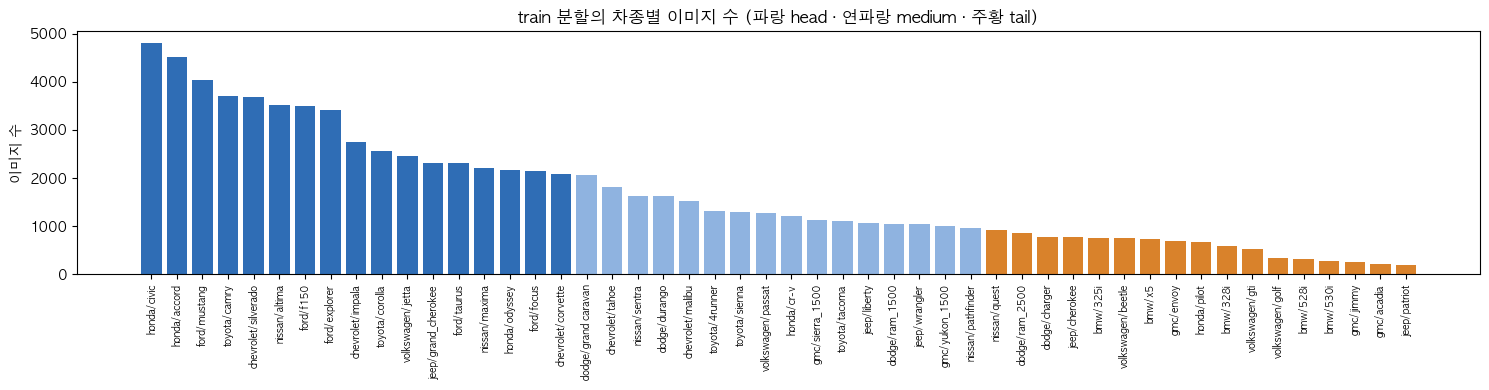

In [6]:
counts = pd.DataFrame({k: d.model_idx.value_counts().sort_index() for k, d in splits.items()})
classes = classes.join(counts.rename(columns=lambda c: f"n_{c}"), on="model_idx")
q1, q2 = np.quantile(classes.n_train, [1 / 3, 2 / 3])
classes["freq_group"] = np.where(classes.n_train >= q2, "head", np.where(classes.n_train >= q1, "medium", "tail"))
info_cols = ["model_idx", "make_model", "make", "model", "make_idx", "body_type", "body_idx", "freq_group", "n_train", "n_val", "n_test"]
classes[info_cols].to_csv(SPLIT_DIR / "class_info.csv", index=False)

display(classes.groupby("freq_group").agg(차종=("model", "size"), train_최소=("n_train", "min"), train_최대=("n_train", "max"))
        .reindex(["head", "medium", "tail"]))
print(f"train 최대/최소 = {classes.n_train.max()} / {classes.n_train.min()} = {classes.n_train.max() / classes.n_train.min():.1f}배")

s = classes.sort_values("n_train", ascending=False)
color = s.freq_group.map({"head": "#2F6DB5", "medium": "#8FB3E0", "tail": "#D9822B"})
fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(s.make_model, s.n_train, color=color)
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.set(title="train 분할의 차종별 이미지 수 (파랑 head · 연파랑 medium · 주황 tail)", ylabel="이미지 수")
plt.tight_layout(); plt.show()

## 5. (선택) 리사이즈 캐시

원본은 600×450 내외 JPEG이다. 학습할 때마다 원본을 열고 줄이면 디스크 읽기와 디코딩이 병목이 된다. 특히 노트북 PC가 그렇다.

그래서 **짧은 변을 256px로 줄인 사본**을 한 번만 만들어 둔다.
- 03 노트북은 캐시가 있으면 자동으로 캐시를 읽는다.
- 맨 위 셀에서 `BUILD_CACHE = True`로 바꾸고 이 셀을 실행한다.
- 이미 만든 파일은 건너뛰므로, 중간에 멈춰도 다시 실행하면 이어서 만든다.

In [7]:
CACHE_DIR = CACHE_ROOT / f"vmmr_{CACHE_SHORT_SIDE}"

def resize_one(rel):
    dst = CACHE_DIR / rel
    if dst.exists():
        return 0
    dst.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(VMMR_ROOT / rel) as im:
        im = im.convert("RGB")
        w, h = im.size
        r = CACHE_SHORT_SIDE / min(w, h)
        if r < 1:
            im = im.resize((round(w * r), round(h * r)), Image.BILINEAR)
        im.save(dst, quality=90)
    return 1

if BUILD_CACHE:
    rels = pd.concat(splits.values()).rel_path.tolist()
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 4)) as ex:
        made = sum(tqdm(ex.map(resize_one, rels), total=len(rels), desc="캐시 생성"))
    print(f"새로 만든 파일 {made:,}개 → {CACHE_DIR}")
else:
    print("BUILD_CACHE = False → 캐시를 만들지 않았습니다. (03 노트북은 원본을 읽습니다)")

BUILD_CACHE = False → 캐시를 만들지 않았습니다. (03 노트북은 원본을 읽습니다)
